# Temporal data validation: Yelp restaurants

Validate temporal coverage before feature engineering or modeling. Status means **snapshot `is_open`**, never status at an event date. Last customer activity is not a closure date. No modeling, text analysis, or predictive features are constructed.

## Design and reproducibility
Requested windows mean two complete calendar years: **2017–2018 = [2017-01-01, 2019-01-01)**, **2018–2019 = [2018-01-01, 2020-01-01)**, **2019–2020 = [2019-01-01, 2021-01-01)**. Annual results also permit one-year interpretation. Dates have no supplied timezone; retain their recorded calendar dates. Events count supplied records/timestamps, not unique visits or customers. Combined counts sum distinct source types without assuming equivalent measurement.

Run all cells from the repository or analysis directory with Python 3.12+ and matplotlib (the project `.venv` suffices). Only restaurant-level aggregates and small monthly tables persist in memory; no datasets or intermediate aggregate files are written. JSON decoding transiently creates text fields but they are immediately discarded and never retained. Source files are streamed once each. The existing EDA gzip reader and availability helper are reused without running its analysis. The filtering script uses exact Restaurants category membership; its source paths are Windows placeholders, so filtering is not rerun.


In [1]:
from collections import Counter
from datetime import datetime
from pathlib import Path
import ast, gzip, json, statistics, time
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis/01_exploratory_analysis.ipynb').is_file())
eda = json.loads((ROOT / 'analysis/01_exploratory_analysis.ipynb').read_text())
setup = ast.parse(''.join(next(c['source'] for c in eda['cells'] if c['cell_type'] == 'code')))
for node in setup.body:
    if isinstance(node, ast.FunctionDef) and node.name in ('availability', 'read_jsonl_gz'):
        exec(compile(ast.Module(body=[node], type_ignores=[]), '<EDA helpers>', 'exec'))
paths = {s: ROOT / 'data' / (s + '.jsonl.gz') for s in ('businesses','reviews','checkins','tips')}
for source, path in paths.items():
    assert availability(path) == 'present', (source, availability(path))
    print(source, f'{path.stat().st_size / 1024**2:.1f} MiB')
rows = list(read_jsonl_gz(paths['businesses']))
status = {r['business_id']: r['is_open'] for r in rows}
assert len(rows) == len(status) and set(status.values()) == {0,1}
assert all('Restaurants' in {c.strip() for c in r['categories'].split(',')} for r in rows)
ids = list(status)
N = len(ids)
base = Counter(status.values())
print('Restaurants:', N, 'snapshot open/closed:', dict(base))
windows = {'2017–2018': (2017,2019), '2018–2019': (2018,2020), '2019–2020': (2019,2021)}

def table(headers, records):
    display(Markdown('| ' + ' | '.join(headers) + ' |\n|' + '|'.join(['---']*len(headers)) + '|\n' + '\n'.join('| ' + ' | '.join(map(str,r)) + ' |' for r in records)))


businesses 7.7 MiB
reviews 1348.9 MiB
checkins 47.6 MiB
tips 48.0 MiB
Restaurants: 52268 snapshot open/closed: {1: 34987, 0: 17281}


## 1. Stream activity and audit date coverage
Each check-in row contains many comma-separated timestamps. Reviews and tips contain one timestamp per row. Missing, invalid, empty, and unmatched records are audited explicitly. Monthly counts use a 24-bit mask for occupied months in each window, allowing continuity checks without retaining individual events. First/last activity is retained per restaurant and source solely for coverage diagnostics.

In [2]:
started = time.perf_counter()
counts, masks, first, last, monthly, audits, lifetime = {}, {}, {}, {}, {}, {}, {}
for source in ('reviews','checkins','tips'):
    counts[source] = {w: Counter() for w in windows}
    masks[source] = {w: Counter() for w in windows}
    first[source], last[source], monthly[source] = {}, {}, Counter()
    audit = Counter()
    lifetime[source] = Counter()
    for record in read_jsonl_gz(paths[source]):
        audit['records'] += 1
        bid = record.get('business_id')
        raw = record.get('date')
        if bid not in status:
            audit['unmatched_records'] += 1
        if not isinstance(raw, str) or not raw.strip():
            audit['empty_date_records'] += 1
            continue
        timestamps = raw.split(',') if source == 'checkins' else [raw]
        for stamp in timestamps:
            try:
                dt = datetime.fromisoformat(stamp.strip())
                if dt.tzinfo is not None:
                    raise ValueError('Unexpected timezone')
            except (TypeError, ValueError):
                audit['invalid_dates'] += 1
                continue
            audit['valid_events'] += 1
            if bid not in status:
                audit['unmatched_events'] += 1
                continue
            audit['matched_events'] += 1
            lifetime[source][bid] += 1
            monthly[source][dt.strftime('%Y-%m')] += 1
            if bid not in first[source] or dt < first[source][bid]: first[source][bid] = dt
            if bid not in last[source] or dt > last[source][bid]: last[source][bid] = dt
            for w, (start, end) in windows.items():
                if start <= dt.year < end:
                    counts[source][w][bid] += 1
                    masks[source][w][bid] |= 1 << ((dt.year-start)*12+dt.month-1)
    audits[source] = audit
    assert sum(monthly[source].values()) == audit['matched_events']
    print(source, dict(audit))
print(f'Streaming elapsed: {time.perf_counter()-started:.1f}s')
table(['Source','Records','Valid events','Restaurants','First date','Last date'],
      [(s, audits[s]['records'], audits[s]['valid_events'],len(first[s]),min(first[s].values()),max(last[s].values())) for s in audits])
combined_first = {i: min(first[s][i] for s in first if i in first[s]) for i in ids}
combined_last = {i: max(last[s][i] for s in last if i in last[s]) for i in ids}
counts['any'], masks['any'] = {}, {}
for w in windows:
    counts['any'][w] = Counter({i: sum(counts[s][w][i] for s in audits) for i in ids})
    masks['any'][w] = {i: masks['reviews'][w][i] | masks['checkins'][w][i] | masks['tips'][w][i] for i in ids}


reviews {'records': 4724471, 'valid_events': 4724471, 'matched_events': 4724471}
checkins {'records': 51302, 'valid_events': 8515127, 'matched_events': 8515127}
tips {'records': 649150, 'valid_events': 649150, 'matched_events': 649150}
Streaming elapsed: 74.9s


| Source | Records | Valid events | Restaurants | First date | Last date |
|---|---|---|---|---|---|
| reviews | 4724471 | 4724471 | 52268 | 2005-02-16 03:23:22 | 2022-01-19 19:48:25 |
| checkins | 51302 | 8515127 | 51302 | 2009-12-30 02:53:27 | 2022-01-19 16:48:37 |
| tips | 649150 | 649150 | 46777 | 2009-04-16 13:11:49 | 2022-01-19 18:42:44 |

## 2. Reconcile with executed original EDA
The expected totals below are taken from saved EDA outputs, not business `review_count`. Assertions fail if source counts, ranges, or restaurant coverage differ. Stored business totals are separately compared to supplied review records; a discrepancy does not identify its cause.

In [3]:
expected = {'reviews': (4724471,4724471,52268,'2005-02-16 03:23:22','2022-01-19 19:48:25'),
            'checkins': (51302,8515127,51302,'2009-12-30 02:53:27','2022-01-19 16:48:37'),
            'tips': (649150,649150,None,'2009-04-16 13:11:49','2022-01-19 18:42:44')}
assert N == 52268 and base == Counter({1:34987,0:17281})
for s, (records,events,coverage,lo,hi) in expected.items():
    assert (audits[s]['records'], audits[s]['valid_events']) == (records,events)
    assert coverage is None or len(first[s]) == coverage
    assert str(min(first[s].values())) == lo and str(max(last[s].values())) == hi
    assert not any(audits[s][k] for k in ('invalid_dates','empty_date_records','unmatched_records'))
mismatches = sum(lifetime['reviews'][r['business_id']] != r['review_count'] for r in rows)
assert mismatches == 32018
assert sum(lifetime['reviews'][i] for i in ids if status[i]==1) == 3773770
assert sum(lifetime['checkins'][i] for i in ids if status[i]==1) == 6757093
eda_text = '\n'.join(''.join(o.get('text',[])) for c in eda['cells'] for o in c.get('outputs',[]))
assert '32,018' in eda_text and '4,724,471' in eda_text
print('All comparable EDA totals, date bounds and coverage reconcile; no discrepancies.')
print('EDA records 32,018 supplied-review-count versus business-review_count mismatches; cause remains unverified.')


All comparable EDA totals, date bounds and coverage reconcile; no discrepancies.
EDA records 32,018 supplied-review-count versus business-review_count mismatches; cause remains unverified.


## 3. Window coverage and absence by snapshot class
Denominators include **all 52,268 restaurants**, including those whose first observed activity is after a window. Zero recorded events means unobserved Yelp activity, not inactivity or closure. Event-type counts overlap at restaurant level; the union is computed per restaurant.

In [4]:
coverage_rows=[]
for w in windows:
    for s in counts:
        c = counts[s][w]
        active = {i for i in ids if c[i]>0}
        op = sum(status[i]==1 for i in active); cl = len(active)-op
        coverage_rows.append((w,s,sum(c.values()),len(active),N-len(active),op,f'{100*op/base[1]:.1f}%',cl,f'{100*cl/base[0]:.1f}%',base[1]-op,base[0]-cl))
        assert op+cl+N-len(active)==N
        assert all(c[i]>=0 for i in ids)
table(['Window','Source','Events','Active','No events','Open active','Open coverage','Closed active','Closed coverage','Open absent','Closed absent'], coverage_rows)
table(['Year','Review events','Check-in events','Tip events'],[(y,*[sum(v for m,v in monthly[s].items() if m.startswith(str(y))) for s in audits]) for y in range(2017,2021)])
# Independent annual/window reconciliation.
for s in audits:
    for w,(start,end) in windows.items():
        assert sum(counts[s][w].values()) == sum(v for m,v in monthly[s].items() if start<=int(m[:4])<end)


| Window | Source | Events | Active | No events | Open active | Open coverage | Closed active | Closed coverage | Open absent | Closed absent |
|---|---|---|---|---|---|---|---|---|---|---|
| 2017–2018 | reviews | 1163141 | 37580 | 14688 | 29028 | 83.0% | 8552 | 49.5% | 5959 | 8729 |
| 2017–2018 | checkins | 1663766 | 35102 | 17166 | 27395 | 78.3% | 7707 | 44.6% | 7592 | 9574 |
| 2017–2018 | tips | 117171 | 25677 | 26591 | 19726 | 56.4% | 5951 | 34.4% | 15261 | 11330 |
| 2017–2018 | any | 2944078 | 38414 | 13854 | 29543 | 84.4% | 8871 | 51.3% | 5444 | 8410 |
| 2018–2019 | reviews | 1218962 | 38402 | 13866 | 31096 | 88.9% | 7306 | 42.3% | 3891 | 9975 |
| 2018–2019 | checkins | 1463364 | 35193 | 17075 | 28870 | 82.5% | 6323 | 36.6% | 6117 | 10958 |
| 2018–2019 | tips | 90959 | 23721 | 28547 | 19254 | 55.0% | 4467 | 25.8% | 15733 | 12814 |
| 2018–2019 | any | 2773285 | 39094 | 13174 | 31512 | 90.1% | 7582 | 43.9% | 3475 | 9699 |
| 2019–2020 | reviews | 966579 | 37873 | 14395 | 32454 | 92.8% | 5419 | 31.4% | 2533 | 11862 |
| 2019–2020 | checkins | 996268 | 33748 | 18520 | 29259 | 83.6% | 4489 | 26.0% | 5728 | 12792 |
| 2019–2020 | tips | 65698 | 20923 | 31345 | 18076 | 51.7% | 2847 | 16.5% | 16911 | 14434 |
| 2019–2020 | any | 2028545 | 38608 | 13660 | 32931 | 94.1% | 5677 | 32.9% | 2056 | 11604 |

| Year | Review events | Check-in events | Tip events |
|---|---|---|---|
| 2017 | 552447 | 892449 | 68205 |
| 2018 | 610694 | 771317 | 48966 |
| 2019 | 608268 | 692047 | 41993 |
| 2020 | 358311 | 304221 | 23705 |

## 4. Threshold sensitivity and unequal observation opportunity
Review thresholds avoid treating a tip as equivalent to a review or check-in. Mixed-source event thresholds are diagnostic only. Active months require any recorded source activity. The first-observed date is a **Yelp history proxy**, not an opening date or actual restaurant age; requiring history before window start excludes newcomers. Eligibility uses only activity before the corresponding cutoff, never future activity or the snapshot label. These are audit cohorts, not constructed model features.

In [5]:
threshold_rows=[]
for w,(start,end) in windows.items():
    for threshold in (1,5,10,20):
        keep = [i for i in ids if counts['reviews'][w][i]>=threshold]
        cl = sum(status[i]==0 for i in keep)
        threshold_rows.append((w,'reviews',threshold,len(keep),len(keep)-cl,cl,f'{100*cl/len(keep):.1f}%'))
    for threshold in (5,10,20):
        keep=[i for i in ids if counts['any'][w][i]>=threshold]
        cl=sum(status[i]==0 for i in keep)
        threshold_rows.append((w,'combined events',threshold,len(keep),len(keep)-cl,cl,f'{100*cl/len(keep):.1f}%'))
table(['Window','Requirement','Minimum','Retained','Open','Closed','Closed share'],threshold_rows)
cohorts={}
continuity=[]
for w,(start,end) in windows.items():
    before=datetime(start,1,1)
    rules={
       'any activity':lambda i: counts['any'][w][i]>0,
       '>=5 reviews':lambda i: counts['reviews'][w][i]>=5,
       '>=5 reviews, >=6 active months':lambda i: counts['reviews'][w][i]>=5 and masks['any'][w][i].bit_count()>=6,
       '>=5 reviews, >=6 active months, prior history':lambda i: counts['reviews'][w][i]>=5 and masks['any'][w][i].bit_count()>=6 and combined_first[i]<before,
    }
    for rule, test in rules.items():
        keep=[i for i in ids if test(i)]; cohorts[w,rule]=keep
        cl=sum(status[i]==0 for i in keep)
        continuity.append((w,rule,len(keep),cl,f'{100*cl/len(keep):.1f}%'))
    active=cohorts[w,'any activity']
    print(w,'active restaurants first observed inside window:',sum(combined_first[i]>=before for i in active),
          '; median active months:',statistics.median(masks['any'][w][i].bit_count() for i in active))
table(['Window','Requirement','Retained','Closed','Closed share'],continuity)
print(f'Full sample closed share: {100*base[0]/N:.2f}%')


2017–2018 active restaurants first observed inside window: 5318 ; median active months: 13.0
2018–2019 active restaurants first observed inside window: 5145 ; median active months: 12.0
2019–2020 active restaurants first observed inside window: 4331 ; median active months: 11.0
Full sample closed share: 33.06%


| Window | Requirement | Minimum | Retained | Open | Closed | Closed share |
|---|---|---|---|---|---|---|
| 2017–2018 | reviews | 1 | 37580 | 29028 | 8552 | 22.8% |
| 2017–2018 | reviews | 5 | 28566 | 22236 | 6330 | 22.2% |
| 2017–2018 | reviews | 10 | 21345 | 16572 | 4773 | 22.4% |
| 2017–2018 | reviews | 20 | 14249 | 11151 | 3098 | 21.7% |
| 2017–2018 | combined events | 5 | 33456 | 26128 | 7328 | 21.9% |
| 2017–2018 | combined events | 10 | 28396 | 22148 | 6248 | 22.0% |
| 2017–2018 | combined events | 20 | 22002 | 17235 | 4767 | 21.7% |
| 2018–2019 | reviews | 1 | 38402 | 31096 | 7306 | 19.0% |
| 2018–2019 | reviews | 5 | 29667 | 24434 | 5233 | 17.6% |
| 2018–2019 | reviews | 10 | 22258 | 18334 | 3924 | 17.6% |
| 2018–2019 | reviews | 20 | 14781 | 12242 | 2539 | 17.2% |
| 2018–2019 | combined events | 5 | 33910 | 27954 | 5956 | 17.6% |
| 2018–2019 | combined events | 10 | 28563 | 23531 | 5032 | 17.6% |
| 2018–2019 | combined events | 20 | 21839 | 18057 | 3782 | 17.3% |
| 2019–2020 | reviews | 1 | 37873 | 32454 | 5419 | 14.3% |
| 2019–2020 | reviews | 5 | 28319 | 24692 | 3627 | 12.8% |
| 2019–2020 | reviews | 10 | 20549 | 18036 | 2513 | 12.2% |
| 2019–2020 | reviews | 20 | 12882 | 11394 | 1488 | 11.6% |
| 2019–2020 | combined events | 5 | 32552 | 28327 | 4225 | 13.0% |
| 2019–2020 | combined events | 10 | 26526 | 23157 | 3369 | 12.7% |
| 2019–2020 | combined events | 20 | 19481 | 17114 | 2367 | 12.2% |

| Window | Requirement | Retained | Closed | Closed share |
|---|---|---|---|---|
| 2017–2018 | any activity | 38414 | 8871 | 23.1% |
| 2017–2018 | >=5 reviews | 28566 | 6330 | 22.2% |
| 2017–2018 | >=5 reviews, >=6 active months | 27010 | 5733 | 21.2% |
| 2017–2018 | >=5 reviews, >=6 active months, prior history | 23619 | 4597 | 19.5% |
| 2018–2019 | any activity | 39094 | 7582 | 19.4% |
| 2018–2019 | >=5 reviews | 29667 | 5233 | 17.6% |
| 2018–2019 | >=5 reviews, >=6 active months | 27840 | 4680 | 16.8% |
| 2018–2019 | >=5 reviews, >=6 active months, prior history | 24474 | 3826 | 15.6% |
| 2019–2020 | any activity | 38608 | 5677 | 14.7% |
| 2019–2020 | >=5 reviews | 28319 | 3627 | 12.8% |
| 2019–2020 | >=5 reviews, >=6 active months | 26326 | 3111 | 11.8% |
| 2019–2020 | >=5 reviews, >=6 active months, prior history | 23562 | 2699 | 11.5% |

## 5. Last observed activity and cutoff leakage audit
Per-restaurant source and combined last timestamps remain in `last` and `combined_last` in memory; only grouped summaries are displayed. Full-history last timestamps are diagnostics and must never enter historical eligibility or features. Events after a cutoff cannot prove a restaurant was continuously open at that cutoff. Events ending before a cutoff cannot prove closure.

In [6]:
table(['Snapshot class','Restaurants','Median first observed','Median last observed','Median observed span (days)'],
 [(label,base[st],sorted(combined_first[i] for i in ids if status[i]==st)[base[st]//2],
   sorted(combined_last[i] for i in ids if status[i]==st)[base[st]//2],
   round(statistics.median((combined_last[i]-combined_first[i]).days for i in ids if status[i]==st))) for st,label in [(1,'open'),(0,'closed')]])
table(['Last observed year','Open','Closed'],[(y,*[sum(combined_last[i].year==y and status[i]==st for i in ids) for st in (1,0)]) for y in sorted({d.year for d in combined_last.values()})])
leak=[]
for w,(start,end) in windows.items():
    cutoff=datetime(end,1,1)
    for st,label in [(1,'open'),(0,'closed')]:
        eligible=[i for i in cohorts[w,'any activity'] if status[i]==st]
        after=sum(combined_last[i]>=cutoff for i in eligible)
        leak.append((w,label,len(eligible),after,f'{100*after/len(eligible):.1f}%'))
table(['Window','Snapshot class','Active cohort','Later recorded activity','Percent'],leak)
assert len(combined_first)==len(combined_last)==N


| Snapshot class | Restaurants | Median first observed | Median last observed | Median observed span (days) |
|---|---|---|---|---|
| open | 34987 | 2012-06-23 21:42:33 | 2021-12-16 13:57:54 | 3279 |
| closed | 17281 | 2011-11-07 02:14:22 | 2017-08-11 01:34:18 | 1537 |

| Last observed year | Open | Closed |
|---|---|---|
| 2007 | 0 | 7 |
| 2008 | 0 | 43 |
| 2009 | 0 | 114 |
| 2010 | 0 | 220 |
| 2011 | 2 | 440 |
| 2012 | 9 | 703 |
| 2013 | 14 | 1072 |
| 2014 | 16 | 1486 |
| 2015 | 31 | 1738 |
| 2016 | 57 | 1725 |
| 2017 | 92 | 1837 |
| 2018 | 228 | 2079 |
| 2019 | 919 | 2326 |
| 2020 | 1890 | 2015 |
| 2021 | 18615 | 1426 |
| 2022 | 13114 | 50 |

| Window | Snapshot class | Active cohort | Later recorded activity | Percent |
|---|---|---|---|---|
| 2017–2018 | open | 29543 | 29223 | 98.9% |
| 2017–2018 | closed | 8871 | 4955 | 55.9% |
| 2018–2019 | open | 31512 | 30365 | 96.4% |
| 2018–2019 | closed | 7582 | 3177 | 41.9% |
| 2019–2020 | open | 32931 | 30122 | 91.5% |
| 2019–2020 | closed | 5677 | 1336 | 23.5% |

## 6. COVID-19 sensitivity
WHO characterized COVID-19 as a pandemic on March 11, 2020 ([WHO timeline](https://www.who.int/emergencies/diseases/novel-coronavirus-2019/interactive-timeline)). March 2020 is used only as a coarse sensitivity boundary; restrictions varied by location and date. Compare identical months across years to reduce seasonal mismatch. Aggregate changes combine platform usage, cohort composition, and pandemic effects and cannot identify a causal effect.

| Source | Matched months | 2019 events | 2020 events | Change |
|---|---|---|---|---|
| reviews | Jan–Feb | 99458 | 91275 | -8.2% |
| reviews | Mar–Dec | 508810 | 267036 | -47.5% |
| checkins | Jan–Feb | 109783 | 104816 | -4.5% |
| checkins | Mar–Dec | 582264 | 199405 | -65.8% |
| tips | Jan–Feb | 7118 | 5615 | -21.1% |
| tips | Mar–Dec | 34875 | 18090 | -48.1% |

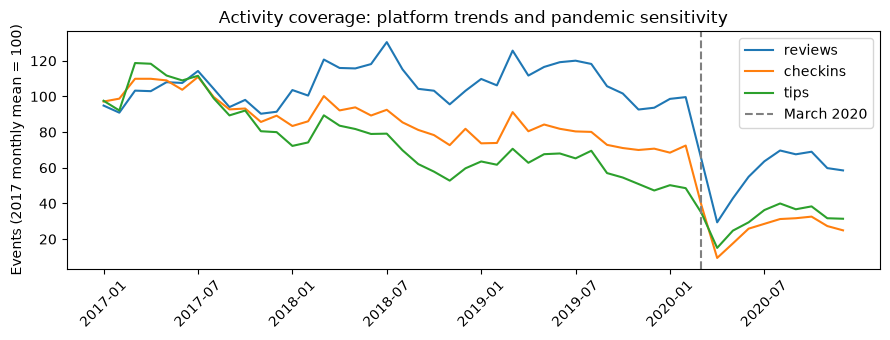

In [7]:
covid=[]
for s in audits:
    for label,months in [('Jan–Feb',range(1,3)),('Mar–Dec',range(3,13))]:
        a=sum(monthly[s][f'2019-{m:02d}'] for m in months)
        b=sum(monthly[s][f'2020-{m:02d}'] for m in months)
        covid.append((s,label,a,b,f'{100*(b/a-1):.1f}%'))
table(['Source','Matched months','2019 events','2020 events','Change'],covid)
fig,ax=plt.subplots(figsize=(9,3.5))
for s in audits:
    ms=[f'{y}-{m:02d}' for y in range(2017,2021) for m in range(1,13)]
    baseline=sum(monthly[s][m] for m in ms[:12])/12
    ax.plot(range(48),[100*monthly[s][m]/baseline for m in ms],label=s)
ax.axvline(38,color='gray',linestyle='--',label='March 2020')
ax.set_xticks(range(0,48,6),ms[::6],rotation=45)
ax.set_ylabel('Events (2017 monthly mean = 100)')
ax.set_title('Activity coverage: platform trends and pandemic sensitivity')
ax.legend(); fig.tight_layout(); plt.show()


## 7. Research methodology recommendation
The following recommendation is populated from executed aggregates rather than assumed sample sizes.

In [8]:
w='2018–2019'
rule='>=5 reviews, >=6 active months'
keep=cohorts[w,rule]; closed=sum(status[i]==0 for i in keep)
strict=cohorts[w,rule+', prior history']
active=cohorts[w,'any activity']
display(Markdown(f"""**Recommended primary observation window: 2018–2019, cutoff January 1, 2020.** It is the latest complete two-year window before the pandemic period, preserves repeated observation opportunity, and avoids mixing the sharp 2020 platform changes into the primary analysis. Use 2017–2018 as a robustness comparison; report 2019–2020 separately as a pandemic sensitivity analysis, not as an interchangeable baseline.

**Usable descriptive sample:** {len(active):,} restaurants have any activity in 2018–2019. A provisional requirement of **at least 5 reviews and activity in at least 6 distinct months** retains **{len(keep):,}** restaurants: **{len(keep)-closed:,} snapshot open**, **{closed:,} snapshot closed ({100*closed/len(keep):.1f}%)**, versus {100*base[0]/N:.1f}% closed in the full sample. This requirement gives a modest repeated-observation floor; it is not a validated statistical power criterion. Compare thresholds of 1, 5, 10 and 20 reviews and report the full eligible denominator. Requiring prior observed history reduces the sample to **{len(strict):,}**; use this as an established-history sensitivity cohort, not evidence of true age. Keep check-ins/tips optional so their platform-specific absence does not define the primary cohort.

**Selection and exposure biases:** activity requirements preferentially retain popular, longer-observed and digitally engaged restaurants, alter the closed share, and exclude establishments with early cessation or recent entry. The window tables demonstrate unequal class coverage. Fixed calendar windows equalize maximum observation time but do not establish comparable restaurant age or actual time at risk. The export already includes only Yelp-listed restaurants and has an observed minimum of five lifetime reviews in the original EDA. Geography, cuisine and platform trends may confound associations. First recorded activity is only a lower bound on documented presence, not an opening date. Source events may include repeated users or duplicate records; exact event deduplication was not audited. Counts describe supplied data, not visits.

**Temporal leakage and label validity:** restrict every future historical calculation and eligibility rule to timestamps strictly before its cutoff. Do not use full-history last/first summaries, snapshot review_count, stars, attributes, hours, or future activity as historical predictors without historical provenance. The first-observed-before-start test can be computed from pre-start events alone. Snapshot is_open has neither a verified reference date nor a closure event date; the activity endpoint in January 2022 is not the label date. Some snapshot-closed restaurants have post-cutoff activity, while absence is common for both labels. A feature window may follow an unknown closure or precede opening. There is no defensible known-open risk set, outcome horizon or event censoring definition here.

**Answer to the original research question:** these data support longitudinal descriptions of Yelp customer activity and associations with eventual snapshot closure status. They **do not currently validate early warning, closure prediction, time-to-closure, or causal effects**. Last activity must never be substituted for closure time. A train/test time split alone cannot repair missing event dates or historic eligibility.

**Next step toward a publishable study:** first obtain independently dated closure/opening events or repeated dated business-status snapshots, document dataset/label provenance and geographic sampling, and validate a known-open cohort at each landmark with a fixed prospective horizon and explicit censoring. Then preregister the question, cohort rules, pandemic handling and power analysis before engineering features. If dated outcomes cannot be obtained, reframe the study as a descriptive longitudinal activity/coverage study by snapshot status, with threshold and age-proxy sensitivity analyses and no predictive claims. Do not begin modeling or sentiment analysis at this stage.

**Validation:** all comparable totals reconcile with the original EDA. Its 32,018 supplied-review-count/business-review_count mismatches remain an unverified provenance issue. Raw datasets were read in place, without copies or aggregate exports.
"""))


**Recommended primary observation window: 2018–2019, cutoff January 1, 2020.** It is the latest complete two-year window before the pandemic period, preserves repeated observation opportunity, and avoids mixing the sharp 2020 platform changes into the primary analysis. Use 2017–2018 as a robustness comparison; report 2019–2020 separately as a pandemic sensitivity analysis, not as an interchangeable baseline.

**Usable descriptive sample:** 39,094 restaurants have any activity in 2018–2019. A provisional requirement of **at least 5 reviews and activity in at least 6 distinct months** retains **27,840** restaurants: **23,160 snapshot open**, **4,680 snapshot closed (16.8%)**, versus 33.1% closed in the full sample. This requirement gives a modest repeated-observation floor; it is not a validated statistical power criterion. Compare thresholds of 1, 5, 10 and 20 reviews and report the full eligible denominator. Requiring prior observed history reduces the sample to **24,474**; use this as an established-history sensitivity cohort, not evidence of true age. Keep check-ins/tips optional so their platform-specific absence does not define the primary cohort.

**Selection and exposure biases:** activity requirements preferentially retain popular, longer-observed and digitally engaged restaurants, alter the closed share, and exclude establishments with early cessation or recent entry. The window tables demonstrate unequal class coverage. Fixed calendar windows equalize maximum observation time but do not establish comparable restaurant age or actual time at risk. The export already includes only Yelp-listed restaurants and has an observed minimum of five lifetime reviews in the original EDA. Geography, cuisine and platform trends may confound associations. First recorded activity is only a lower bound on documented presence, not an opening date. Source events may include repeated users or duplicate records; exact event deduplication was not audited. Counts describe supplied data, not visits.

**Temporal leakage and label validity:** restrict every future historical calculation and eligibility rule to timestamps strictly before its cutoff. Do not use full-history last/first summaries, snapshot review_count, stars, attributes, hours, or future activity as historical predictors without historical provenance. The first-observed-before-start test can be computed from pre-start events alone. Snapshot is_open has neither a verified reference date nor a closure event date; the activity endpoint in January 2022 is not the label date. Some snapshot-closed restaurants have post-cutoff activity, while absence is common for both labels. A feature window may follow an unknown closure or precede opening. There is no defensible known-open risk set, outcome horizon or event censoring definition here.

**Answer to the original research question:** these data support longitudinal descriptions of Yelp customer activity and associations with eventual snapshot closure status. They **do not currently validate early warning, closure prediction, time-to-closure, or causal effects**. Last activity must never be substituted for closure time. A train/test time split alone cannot repair missing event dates or historic eligibility.

**Next step toward a publishable study:** first obtain independently dated closure/opening events or repeated dated business-status snapshots, document dataset/label provenance and geographic sampling, and validate a known-open cohort at each landmark with a fixed prospective horizon and explicit censoring. Then preregister the question, cohort rules, pandemic handling and power analysis before engineering features. If dated outcomes cannot be obtained, reframe the study as a descriptive longitudinal activity/coverage study by snapshot status, with threshold and age-proxy sensitivity analyses and no predictive claims. Do not begin modeling or sentiment analysis at this stage.

**Validation:** all comparable totals reconcile with the original EDA. Its 32,018 supplied-review-count/business-review_count mismatches remain an unverified provenance issue. Raw datasets were read in place, without copies or aggregate exports.
